## 3. The belief is recovered in the deep representation

A single token is uninformative about the state, so the belief is reconstructed only in the deep
reps as context accumulates. We compare the **belief-state trajectory** (per-position forward-
algorithm belief vs the network's hidden), with a **linear probe** and **CCA** — the figure
overlays the two trajectories in belief-ring coordinates (they coincide over the whole context).

In [18]:
import sys
import numpy as np, torch
from pyprojroot import here
sys.path.append(str(here()))
from src.code.geometry import predicted_geometry, spectral_hmm, spectral_beliefs
from src.code.eval import cka, cca
from src.code.train import train_inline
from src.code import plot_utils
import matplotlib.pyplot as plt

## Setup: train a transformer on ring-HMM emissions

`runner=hmm` (see `conf/runner/hmm.yaml`) is a transformer sized to reach Bayes on belief-tracking.
We train once and sample a fixed set of sequences everything below reuses.

In [11]:
model, ds, ev, hist = train_inline(['runner=hmm', 'eval_kwargs.output_hidden_states=true'])  # emission=bump
n = ds.n_states
E_lat = predicted_geometry(ds.latent_conditional)                     # predicted latent ring

B, L = 128, 40                                                        # fixed eval sequences
s = torch.empty(B, L, dtype=torch.long, device=ds.device)
s[:, 0] = torch.multinomial(ds.pi, B, replacement=True, generator=ds.rng)
for t in range(1, L):
    s[:, t] = torch.multinomial(ds.T[s[:, t-1]], 1, generator=ds.rng).squeeze(1)
x = torch.multinomial(ds.Em[s.reshape(-1)], 1, generator=ds.rng).reshape(B, L)
ids = torch.cat([torch.full((B,1), ds.start_token, dtype=torch.long, device=ds.device), x], 1)
with torch.no_grad():
    out = model(ids, output_hidden_states=True)
H = out['hidden_states'][-1][:, 1:].reshape(-1, model.config.hidden_size).cpu().numpy()
bel = ds.forward_algorithm(x); belf = bel.reshape(-1, n).cpu().numpy()  # exact beliefs
st = s.cpu().numpy().reshape(-1)                                       # true latent state per position

INFO:src.code.models:Number of parameters: 398336


Current GPUs:
    GPU 0: NVIDIA H200
wandb disabled (wandb.enabled=false); skipping wandb.init.
Model dims from dataset: vocab_size=10, max_position_embeddings=41


Step,Training Loss
100,2.144432
200,2.130735
300,2.128943
400,2.128557
500,2.130325
600,2.128607
700,2.129299
800,2.128324
900,2.129422
1000,2.128336


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 1. The belief geometry (closed form)

No training needed: the predicted latent geometry is the ring, and the exact belief (forward
algorithm) lives on that ring at a radius set by the emission SNR.

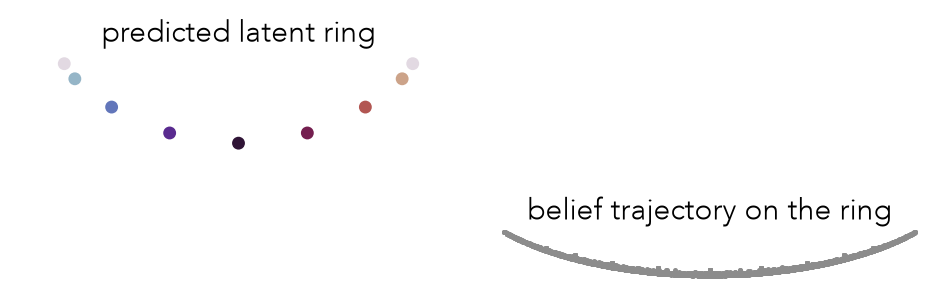

In [12]:
code = belf @ E_lat                                                   # belief-weighted ring position
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
plot_utils.scatter_geometry(ax[0], E_lat[:, :2], 'predicted latent ring')
ax[1].scatter(code[:, 0], code[:, 1], s=4, c='0.55'); ax[1].set_aspect('equal')
ax[1].set_title('belief trajectory on the ring'); plot_utils.FIG.clean(ax[1])
fig.tight_layout();

## 2. Behavior reaches Bayes

In [13]:
p_model = torch.softmax(out['logits'][:, :-1][..., ds.item_tokens], -1).cpu().numpy()
p_bayes = torch.cat([(ds.pi@ds.Em).expand(B,1,-1), (bel[:, :-1]@ds.T)@ds.Em], 1).cpu().numpy()
kl = lambda p,q: float((p*(np.log(p+1e-9)-np.log(q+1e-9))).sum(-1).mean())
print(f'KL(bayes || model) = {kl(p_bayes, p_model):.4f}   (marginal baseline '
      f'{kl(p_bayes, (ds.pi@ds.Em).cpu().numpy()[None,None]):.3f})')

KL(bayes || model) = 0.0004   (marginal baseline 0.056)


## 3. The belief is recovered in the deep representation

A single token is uninformative about the state, so the ring is absent from the token embedding but
reconstructed in the deep reps. Quantify with a **linear probe** and **CCA**; the figure maps each
hidden state linearly to the belief ring (colored by the true state).

belief linearly represented:  probe R2 = 0.997   CCA(hidden, belief trajectory) = 0.886


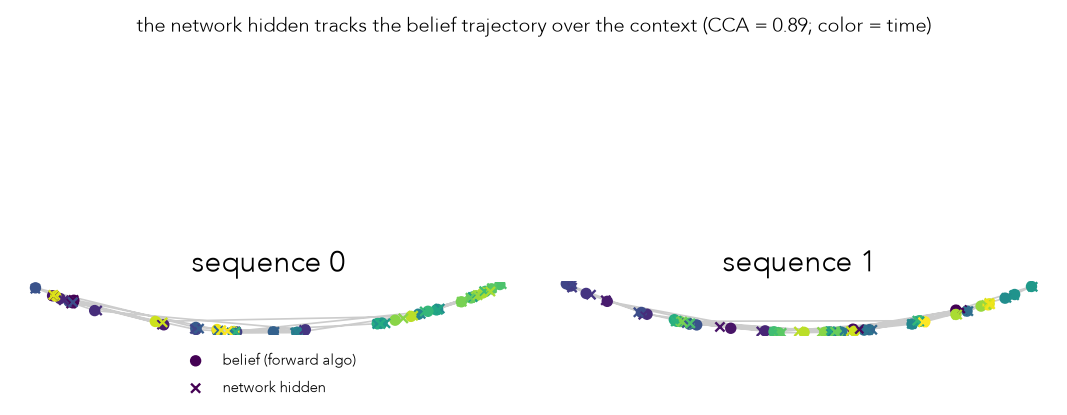

In [14]:
ntr = int(0.8*len(H)); lam = 1e-2                                     # linear probe hidden -> belief
Xtr = np.c_[H[:ntr], np.ones(ntr)]; Xte = np.c_[H[ntr:], np.ones(len(H)-ntr)]
W = np.linalg.solve(Xtr.T@Xtr + lam*np.eye(Xtr.shape[1]), Xtr.T@belf[:ntr]); pred = Xte@W
R2 = 1 - ((belf[ntr:]-pred)**2).sum() / ((belf[ntr:]-belf[ntr:].mean(0))**2).sum()
print(f'belief linearly represented:  probe R2 = {R2:.3f}   CCA(hidden, belief trajectory) = {cca(H, belf):.3f}')

# Compare the belief-state TRAJECTORY: forward-algorithm belief vs the network's hidden, per position.
# Both shown as the 2-D belief-ring coordinate (belief-weighted ring position); network mapped by a
# single linear readout. If the network tracks the belief, the two trajectories coincide.
bcode = (belf @ E_lat[:, :2]).reshape(B, L, 2)                        # forward-algorithm belief traj
Wc = np.linalg.lstsq(np.c_[H, np.ones(len(H))], belf @ E_lat[:, :2], rcond=None)[0]
ncode = (np.c_[H, np.ones(len(H))] @ Wc).reshape(B, L, 2)             # network hidden, mapped
fig, ax = plt.subplots(1, 2, figsize=(9, 4.4))
for a, seq in zip(ax, [0, 1]):
    a.plot(bcode[seq, :, 0], bcode[seq, :, 1], '-', color='0.8', lw=1, zorder=0)
    a.scatter(bcode[seq, :, 0], bcode[seq, :, 1], c=range(L), cmap='viridis', s=34, zorder=1, label='belief (forward algo)')
    a.scatter(ncode[seq, :, 0], ncode[seq, :, 1], c=range(L), cmap='viridis', marker='x', s=30, lw=1.4, zorder=2, label='network hidden')
    a.set_aspect('equal'); plot_utils.FIG.clean(a); a.set_title(f'sequence {seq}')
ax[0].legend(frameon=False, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.02))
fig.suptitle(f'the network hidden tracks the belief trajectory over the context '
             f'(CCA = {cca(H, belf):.2f}; color = time)', y=1.02)
fig.tight_layout();

## 4. The network learns the spectral (observable-operator) representation

The spectral HMM (Hsu-Kakade-Zhang) recovers the belief in closed form from *observed* co-occurrence
moments (SVD of the bigram co-occurrence + per-symbol operators); it matches the forward algorithm
exactly up to a linear map. The network's hidden states align with the **spectral basis specifically**
(high CKA), not the raw belief simplex nor a generic (ZCA-whitened) belief — evidence it implements
the spectral computation. (CCA is high for all three, since they're the same belief up to a linear map.)

In [15]:
pi, T, Em = ds.pi.cpu().numpy(), ds.T.cpu().numpy(), ds.Em.cpu().numpy()
U, Bops, b1, b_inf = spectral_hmm(pi, T, Em)
spec = spectral_beliefs(Bops, b1, b_inf, x.cpu().numpy()).reshape(-1, n)
Fc = belf - belf.mean(0); cov = Fc.T@Fc/len(Fc); w, V = np.linalg.eigh(cov)
Fwhite = Fc @ (V @ np.diag(1/np.sqrt(np.clip(w,1e-9,None))) @ V.T)     # ZCA-whitened belief (control)
print('spectral oracle vs forward algorithm:  CCA =', round(cca(spec, belf), 3),
      '(identical up to a linear map)\n')
print(f"{'target':>16s} {'CCA':>7s} {'CKA':>7s}")
for name, Y in [('forward belief', belf), ('spectral belief', spec), ('whitened-fwd', Fwhite)]:
    print(f'{name:>16s} {cca(H, Y):7.3f} {cka(H, Y):7.3f}')
print('\n-> high CKA to the spectral basis but not to forward/whitened: the network is in the'
      ' observable-operator basis, not a generic whitening.')

spectral oracle vs forward algorithm:  CCA = 1.0 (identical up to a linear map)

          target     CCA     CKA
  forward belief   0.886   0.983
 spectral belief   0.991   0.996
    whitened-fwd   0.886   0.363

-> high CKA to the spectral basis but not to forward/whitened: the network is in the observable-operator basis, not a generic whitening.


Since the network aligns with the spectral basis up to a **rotation** (high CKA), we can overlay the
two belief paths directly — no fitted projection, just an orthogonal Procrustes rotation of the
network hidden onto the spectral belief. The path panels put the spectral-algorithm trajectory (●)
beside the rotation-aligned transformer trajectory (×) for a couple of sequences; the parity panel
shows the two coincide coordinate-for-coordinate (rotation only, R² ≈ 0.87). The paths look jagged
because the belief itself does a jumpy walk and the spectral ring is genuinely non-planar (~44% of
its variance is off any 2-D plane) — not because the two disagree.

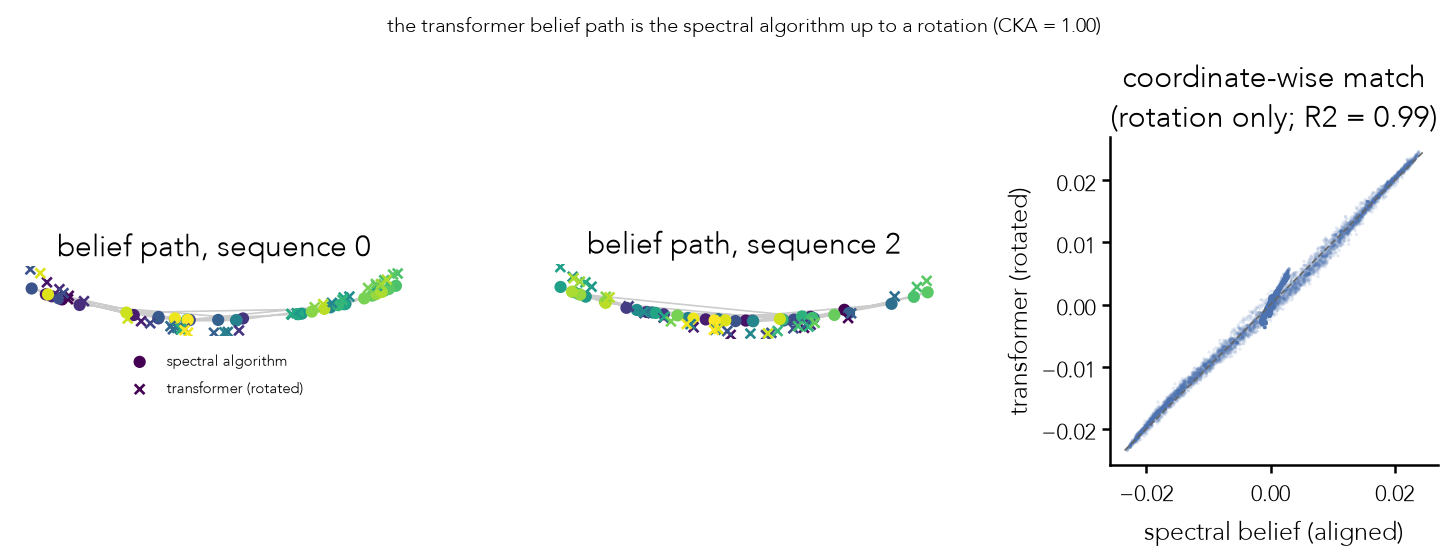

In [16]:
from numpy.linalg import svd as _svd, norm as _norm
from scipy.linalg import orthogonal_procrustes

# rotation-only alignment (justified by the high CKA above): top-n PCA of the hidden, then an
# orthogonal Procrustes rotation onto the spectral belief. Center + unit-norm both first, since a
# rotation cannot fix a scale mismatch (the hidden is far larger than the O(1) belief vector).
Sc = spec - spec.mean(0); Sc /= _norm(Sc)
Hn = (H - H.mean(0)) @ _svd(H - H.mean(0), full_matrices=False)[2][:n].T; Hn /= _norm(Hn)
Rrot, _ = orthogonal_procrustes(Hn, Sc); Hrot = Hn @ Rrot
r2 = 1 - _norm(Hrot - Sc) ** 2 / _norm(Sc) ** 2

# viewing plane = ring plane of the state-averaged spectral belief (the noisy per-token cloud has no
# cleaner 2-D view: the spectral ring is genuinely non-planar).
means = np.stack([Sc[st == k].mean(0) for k in range(n)])
A = _svd(means - means.mean(0), full_matrices=False)[2][:2]
pS = (Sc @ A.T).reshape(B, L, 2); pT = (Hrot @ A.T).reshape(B, L, 2)

fig, ax = plt.subplots(1, 3, figsize=(12.5, 4.3))
for a, seq in zip(ax[:2], [0, 2]):
    a.plot(pS[seq, :, 0], pS[seq, :, 1], '-', color='0.8', lw=1, zorder=0)
    a.scatter(pS[seq, :, 0], pS[seq, :, 1], c=range(L), cmap='viridis', s=40, zorder=1, label='spectral algorithm')
    a.scatter(pT[seq, :, 0], pT[seq, :, 1], c=range(L), cmap='viridis', marker='x', s=34, lw=1.6, zorder=2, label='transformer (rotated)')
    a.set_aspect('equal'); plot_utils.FIG.clean(a); a.set_title(f'belief path, sequence {seq}')
ax[0].legend(frameon=False, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.02))
ax[2].scatter(Sc.ravel(), Hrot.ravel(), s=4, alpha=0.15, color=plot_utils.FIG.colors['blue'], edgecolors='none')
lim = [min(Sc.min(), Hrot.min()), max(Sc.max(), Hrot.max())]
ax[2].plot(lim, lim, '--', color='0.4', lw=1)
ax[2].set_xlabel('spectral belief (aligned)'); ax[2].set_ylabel('transformer (rotated)')
ax[2].set_title(f'coordinate-wise match\n(rotation only; R2 = {r2:.2f})')
plot_utils.FIG.style_axes(ax[2]); ax[2].set_aspect('equal')
fig.suptitle(f'the transformer belief path is the spectral algorithm up to a rotation (CKA = {cka(H, spec):.2f})', y=1.02)
fig.tight_layout();

### Which computation does the network implement? Align each theory *toward the network*.

The transformer is the empirical object; the forward algorithm and the spectral algorithm are two
idealized belief representations that differ only by an invertible linear map. So we take the network
as the reference and align each theory toward it (columns = model / forward / spectral, aligned to the
network's own ring plane; color = latent state):

- **CCA row (linear map).** Both theories reconstruct the network almost perfectly (R² ≈ 1) — the
  belief is linearly present either way, so a linear metric can't tell them apart.
- **Rotation row (orthogonal).** A rotation can't stretch, so it *can* tell them apart: the **spectral**
  belief still matches the network (R² ≈ 0.99) while the **forward** belief does not (R² ≈ 0.82).
  Since the two differ only by a linear map, a rotation singling out spectral means the network holds
  the belief in the spectral (observable-operator) basis specifically.

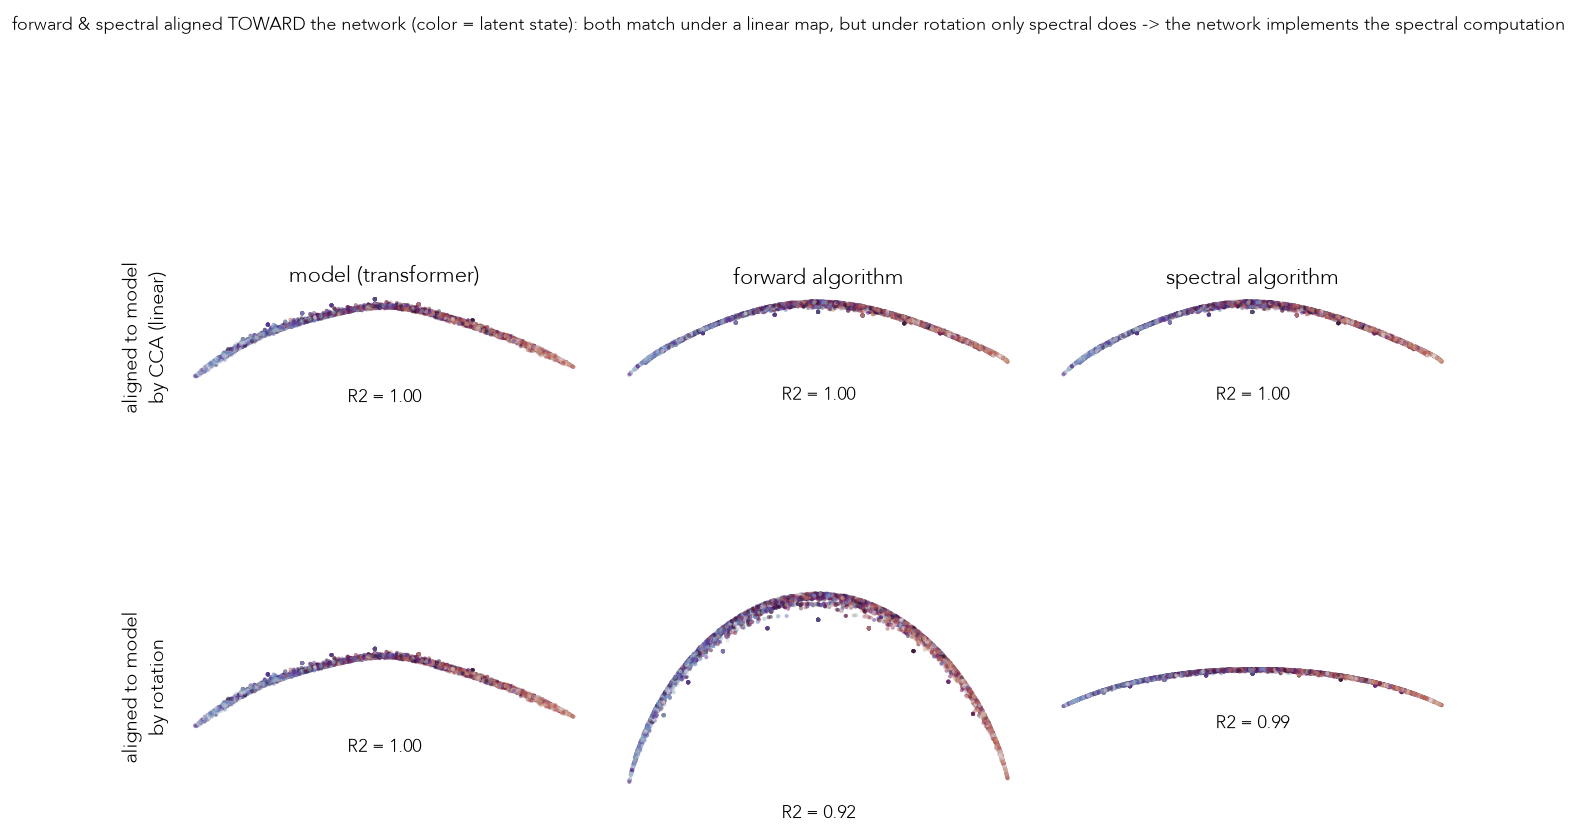

In [17]:
from numpy.linalg import svd as _svd, norm as _norm, lstsq as _lstsq
from scipy.linalg import orthogonal_procrustes

def _unit(A): A = A - A.mean(0); return A / _norm(A)
# reference = the trained network (top-n PCA of the hidden), unit-normed; the two theories align to IT
Hn = _unit(H) @ _svd(_unit(H), full_matrices=False)[2][:n].T; Hn /= _norm(Hn)
meansH = np.stack([Hn[st == k].mean(0) for k in range(n)])
axesH = _svd(meansH - meansH.mean(0), full_matrices=False)[2][:2]     # the network's own ring plane
def _view(C): C = C - C.mean(0); return C / C.std()                   # comparable panel scale

def _cca(Y):                             # best linear map Y -> network; R2 of reconstructing the network
    Ya = np.c_[Y, np.ones(len(Y))]; P = Ya @ _lstsq(Ya, Hn, rcond=None)[0]
    return P @ axesH.T, 1 - _norm(P - Hn) ** 2 / _norm(Hn - Hn.mean(0)) ** 2
def _rot(Y):                             # rotation-only Y -> network
    Yr = _unit(Y) @ _svd(_unit(Y), full_matrices=False)[2][:n].T; Yr /= _norm(Yr)
    R, _ = orthogonal_procrustes(Yr, Hn); P = Yr @ R
    return P @ axesH.T, 1 - _norm(P - Hn) ** 2 / _norm(Hn) ** 2

cols = [('model (transformer)', None), ('forward algorithm', belf), ('spectral algorithm', spec)]
rows = [('aligned to model\nby CCA (linear)', _cca), ('aligned to model\nby rotation', _rot)]
fig, ax = plt.subplots(2, 3, figsize=(11.5, 8))
for r, (rlab, fn) in enumerate(rows):
    for c, (clab, Y) in enumerate(cols):
        coords, r2 = (Hn @ axesH.T, 1.0) if Y is None else fn(Y)     # model column = reference
        a = ax[r, c]; coords = _view(coords)
        a.scatter(coords[:, 0], coords[:, 1], s=6, c=st, cmap=plot_utils.FIG.cyclic_cmap, alpha=0.5, edgecolors='none')
        a.set_aspect('equal'); plot_utils.FIG.clean(a)
        if r == 0: a.set_title(clab, fontsize=13, pad=8)
        if c == 0: a.set_ylabel(rlab, fontsize=12)
        a.text(0.5, -0.04, f'R2 = {r2:.2f}', transform=a.transAxes, ha='center', va='top', fontsize=11)
fig.suptitle('forward & spectral aligned TOWARD the network (color = latent state): both match under a linear '
             'map, but under rotation only spectral does -> the network implements the spectral computation', y=1.0, fontsize=11)
fig.tight_layout();